# 07 · Red neuronal multitarea (una red → H1, H4, H5, H6)

Generado por `PYTHONPATH=src python -m usab_ds stage7`. Tronco MLP compartido + 4 cabezas sigmoides (Caruana, 1997); pérdida BCE enmascarada (H5 solo donde es evaluable) y ponderada por clase; ensamble de semillas. Partición 70/30 por participante; configuración y umbrales elegidos solo con validación cruzada en el 70 %.

In [1]:
import pathlib, sys, joblib
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
R = ROOT / 'reports' / '07_red_neuronal_multitarea'; RF = ROOT / 'reports' / '06_modelo_multietiqueta'
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
r1, r2 = pd.read_csv(R / 'busqueda_ronda1_cv_70.csv'), pd.read_csv(R / 'busqueda_ronda2_cv_70.csv')
per = pd.read_csv(R / 'resultados_test_30_por_heuristica.csv'); glob = pd.read_csv(R / 'resultados_test_30_global.csv')
pred = pd.read_csv(R / 'predicciones_test.csv')
b = joblib.load(ROOT / 'models' / 'red_neuronal_multitarea_H1_H4_H5_H6.joblib'); b['config']

{'hidden': (512, 256),
 'dropout': 0.2,
 'weight_decay': 0.1,
 'lr': 0.003,
 'act': 'elu',
 'head_hidden': 0,
 'batch': 16,
 'n_seeds': 10,
 'max_epochs': 300,
 'patience': 25}

## 1. Búsqueda de configuraciones (validación cruzada en el 70 %)

In [2]:
print(f'Ronda 1: {len(r1)} configuraciones · Ronda 2: {len(r2)} configuraciones')
cols = ['variables','hidden','dropout','weight_decay','lr','act','head_hidden','batch','n_seeds','cv_f1_macro','cv_mcc_macro','cv_auc_H1','cv_auc_H4','cv_auc_H5','cv_auc_H6']
pd.concat([r1.assign(ronda=1), r2.assign(ronda=2)]).sort_values('cv_mcc_macro', ascending=False)[['ronda'] + cols].head(10).round(3)

Ronda 1: 120 configuraciones · Ronda 2: 30 configuraciones


,ronda,variables,hidden,dropout,weight_decay,lr,act,head_hidden,batch,n_seeds,cv_f1_macro,cv_mcc_macro,cv_auc_H1,cv_auc_H4,cv_auc_H5,cv_auc_H6
0,2,completo,"(512, 256)",0.2,0.10,0.003,elu,0,16,10,0.603,0.374,0.713,0.587,0.705,0.679
0,1,completo,"(256, 128)",0.1,0.05,0.003,elu,0,32,5,0.588,0.369,0.699,0.577,0.731,0.639
1,2,completo,"(256, 128)",0.3,0.01,0.003,elu,0,32,10,0.581,0.340,0.703,0.621,0.662,0.639
2,2,completo,"(512, 256)",0.3,0.05,0.001,elu,0,32,10,0.578,0.328,0.679,0.611,0.610,0.651
3,2,completo,"(512, 256)",0.1,0.10,0.003,elu,16,16,10,0.582,0.322,0.705,0.622,0.688,0.653
4,2,completo,"(256, 128, 64)",0.1,0.10,0.003,elu,16,16,10,0.578,0.314,0.669,0.583,0.692,0.648
5,2,completo,"(256, 128, 64)",0.1,0.05,0.001,elu,16,32,10,0.579,0.311,0.669,0.565,0.669,0.657
1,1,completo,"(256, 128)",0.3,0.01,0.001,elu,0,16,5,0.572,0.311,0.693,0.566,0.666,0.627
6,2,completo,"(256, 128, 64)",0.2,0.01,0.001,elu,16,16,10,0.563,0.303,0.655,0.554,0.662,0.636
7,2,completo,"(512, 256)",0.3,0.05,0.001,elu,0,16,10,0.571,0.300,0.697,0.597,0.656,0.647


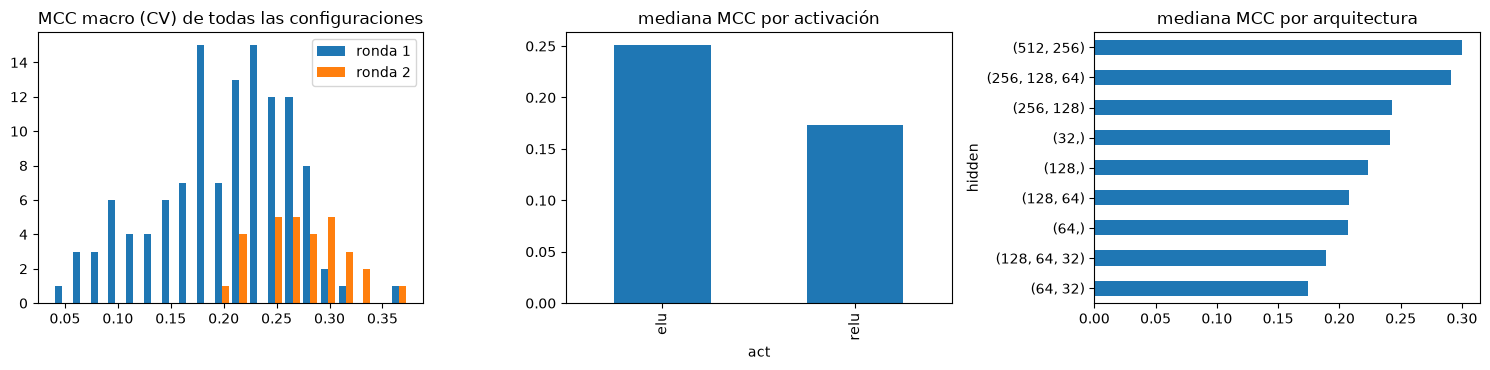

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
allr = pd.concat([r1.assign(ronda='1'), r2.assign(ronda='2')])
axes[0].hist([r1.cv_mcc_macro, r2.cv_mcc_macro], bins=20, label=['ronda 1', 'ronda 2']); axes[0].legend(); axes[0].set_title('MCC macro (CV) de todas las configuraciones')
allr.groupby('act').cv_mcc_macro.median().plot.bar(ax=axes[1], title='mediana MCC por activación')
allr.groupby('hidden').cv_mcc_macro.median().sort_values().plot.barh(ax=axes[2], title='mediana MCC por arquitectura')
plt.tight_layout()

## 2. Red seleccionada en el 30 % de prueba

In [4]:
per[['heuristica','n','positivos','umbral','exactitud','exactitud_balanceada','precision','sensibilidad','especificidad','f1','mcc','kappa','roc_auc','pr_auc']].round(3)

,heuristica,n,positivos,umbral,exactitud,exactitud_balanceada,precision,sensibilidad,especificidad,f1,mcc,kappa,roc_auc,pr_auc
0,H1,93,32,0.535,0.785,0.777,0.667,0.750,0.803,0.706,0.540,0.537,0.815,0.775
1,H4,93,17,0.628,0.785,0.709,0.435,0.588,0.829,0.500,0.374,0.367,0.733,0.586
2,H5,18,11,0.414,0.833,0.838,0.900,0.818,0.857,0.857,0.663,0.658,0.922,0.953
3,H6,93,32,0.551,0.763,0.716,0.692,0.562,0.869,0.621,0.457,0.451,0.797,0.757


In [5]:
per[['heuristica','f1_ic95','mcc_ic95','sensibilidad_ic95','especificidad_ic95','roc_auc_ic95','mcnemar_p_vs_base']]

,heuristica,f1_ic95,mcc_ic95,sensibilidad_ic95,especificidad_ic95,roc_auc_ic95,mcnemar_p_vs_base
0,H1,"[0.596, 0.785]","[0.439, 0.619]","[0.718, 0.786]","[0.700, 0.870]","[0.754, 0.895]",0.065245
1,H4,"[0.312, 0.625]","[0.191, 0.535]","[0.417, 0.750]","[0.706, 0.924]","[0.606, 0.830]",0.677639
2,H5,"[0.625, 1.000]","[0.258, 1.000]","[0.556, 1.000]","[0.625, 1.000]","[0.792, 1.000]",0.289062
3,H6,"[0.416, 0.787]","[0.216, 0.695]","[0.345, 0.778]","[0.818, 0.918]","[0.680, 0.930]",0.075519


In [6]:
glob.drop(columns=[c for c in glob.columns if c in ('max_epochs','patience')]).round(3)

,variables,hidden,dropout,weight_decay,lr,act,head_hidden,batch,n_seeds,f1_macro,mcc_macro,f1_micro_H1H4H6,hamming_loss_H1H4H6,exact_match_H1H4H6
0,completo,"(512, 256)",0.2,0.1,0.003,elu,0,16,10,0.671,0.508,0.627,0.222,0.495


## 3. Red neuronal vs Random Forest multi-salida (mismo 30 %)

,RN_f1,RF_f1,RN_mcc,RF_mcc,RN_sensibilidad,RF_sensibilidad,RN_especificidad,RF_especificidad,RN_roc_auc,RF_roc_auc,RN_pr_auc,RF_pr_auc
heuristica,,,,,,,,,,,,
H1,0.706,0.800,0.540,0.693,0.750,0.812,0.803,0.885,0.815,0.856,0.775,0.855
H4,0.500,0.490,0.374,0.360,0.588,0.706,0.829,0.737,0.733,0.824,0.586,0.666
H5,0.857,0.880,0.663,0.670,0.818,1.000,0.857,0.571,0.922,0.870,0.953,0.912
H6,0.621,0.657,0.457,0.457,0.562,0.719,0.869,0.754,0.797,0.847,0.757,0.776


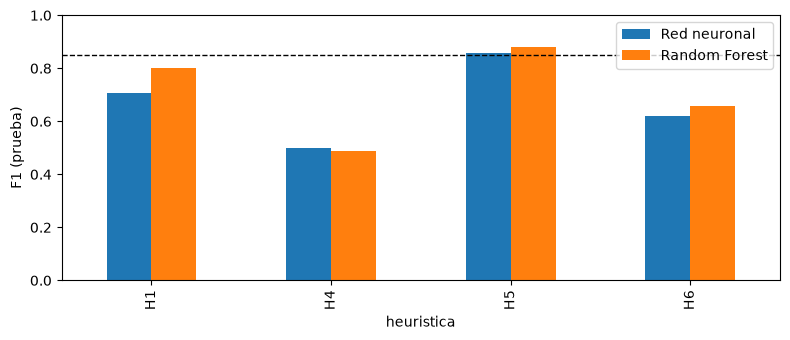

In [7]:
rf = pd.read_csv(RF / 'resultados_test_30_por_heuristica.csv')
m = ['f1','mcc','sensibilidad','especificidad','roc_auc','pr_auc']
cmp = per.set_index('heuristica')[m].add_prefix('RN_').join(rf.set_index('heuristica')[m].add_prefix('RF_'))
display(cmp[[f'{p}_{k}' for k in m for p in ('RN', 'RF')]].round(3))
fig, ax = plt.subplots(figsize=(8, 3.5))
pd.DataFrame({'Red neuronal': per.set_index('heuristica').f1, 'Random Forest': rf.set_index('heuristica').f1}).plot.bar(ax=ax)
ax.axhline(0.85, ls='--', c='k', lw=1); ax.set_ylabel('F1 (prueba)'); ax.set_ylim(0, 1); plt.tight_layout()

## 4. Curvas ROC y matrices de confusión de la red

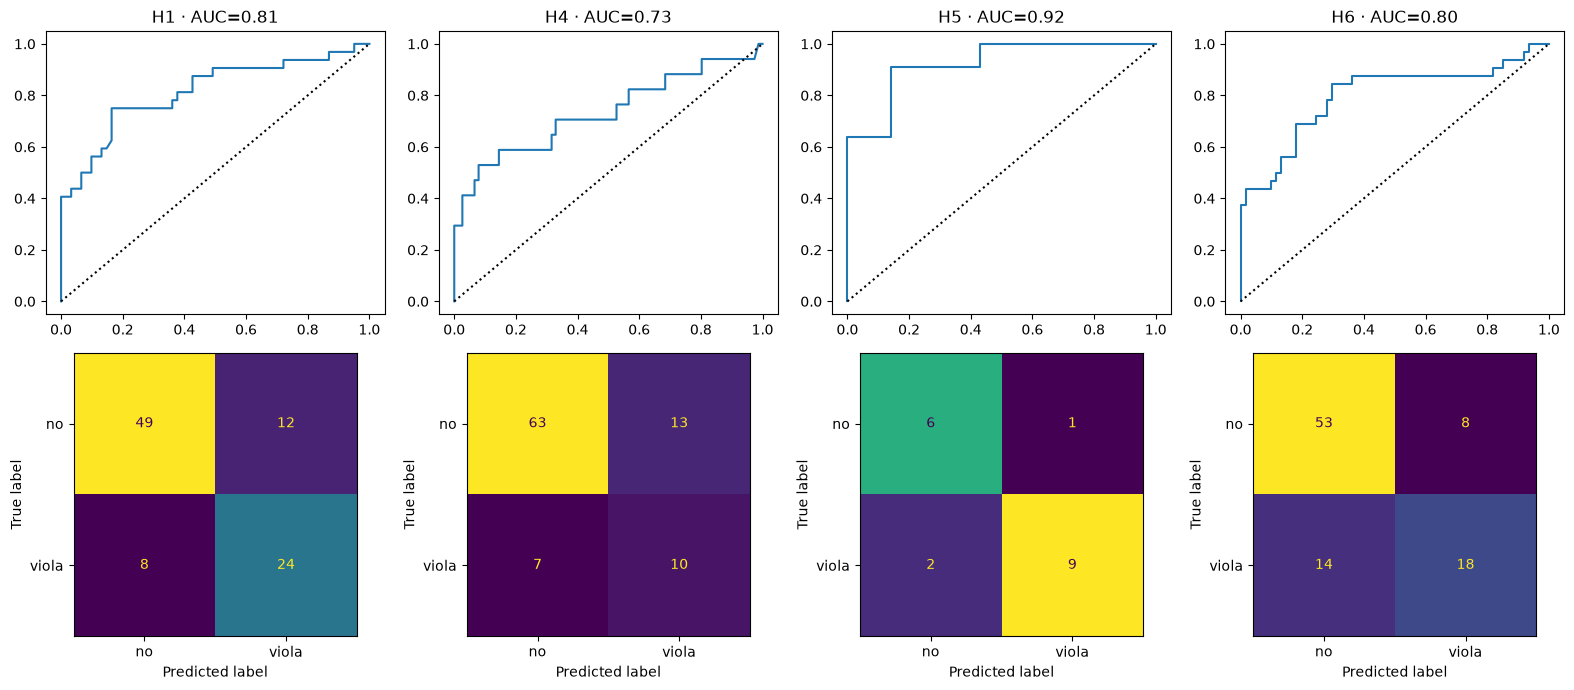

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, (_, r) in enumerate(per.iterrows()):
    h = r.heuristica; d = pred[pred[f'real_y_{h}'].notna()]
    y, p = d[f'real_y_{h}'].astype(int), d[f'prob_y_{h}']
    fpr, tpr, _ = roc_curve(y, p)
    axes[0, i].plot(fpr, tpr); axes[0, i].plot([0, 1], [0, 1], 'k:'); axes[0, i].set_title(f'{h} · AUC={r.roc_auc:.2f}')
    ConfusionMatrixDisplay.from_predictions(y, (p >= r.umbral).astype(int), ax=axes[1, i], colorbar=False, display_labels=['no', 'viola'])
plt.tight_layout()